# AnomAR1 – overview

**Question:** how strong is the simple statistical baseline that the team uses to score every other model?
AnomAR1 says: flooded area h steps ahead = the **normal level** at the target step + φ^h × **today's deviation**.

This notebook is the starting point. Each section runs the real functions in `src/AnomAR1/` and ends with a
**Details** line naming the file and function to open for a closer look. The notebook holds no logic of its own;
results are read from `results/AnomAR1/` (produced by `anomar1_forecast.py`, `anomar1_evaluate.py`,
`anomar1_diagnostics.py` and `anomar1_eda.py`).

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parents[1]          # notebooks/AnomAR1 -> repo root
sys.path.insert(0, str(ROOT / "src" / "AnomAR1"))
TABLES = ROOT / "results" / "AnomAR1" / "tables"
FIGURES = ROOT / "results" / "AnomAR1" / "figures"

from anomar1_data import load_config, load_flood_matrix, step_to_doy
from anomar1_protocol import (HORIZONS, HORIZON_DAYS, build_rows, climatology, estimate_phi,
                              forecast_origins, training_seasons)

## 1. One-sentence conclusion

In [2]:
tests = pd.read_csv(TABLES / "vs_anom_ar1.csv")
for row in tests.itertuples():
    print(f"{row.model:<12} {HORIZON_DAYS[row.h]:>2} days: RMSE / AnomAR1 = {row.rmse_ratio:.3f}, "
          f"wins {row.wins}/{row.n_seasons} seasons, Holm p = {row.p_t_holm:.4f}, TOST p = {row.p_tost:.4f}")

anom_ar1_w7   8 days: RMSE / AnomAR1 = 0.994, wins 8/11 seasons, Holm p = 0.6650, TOST p = 0.0000
anom_ar1_w7  16 days: RMSE / AnomAR1 = 0.985, wins 9/11 seasons, Holm p = 0.1151, TOST p = 0.0001
anom_ar1_w7  32 days: RMSE / AnomAR1 = 0.997, wins 7/11 seasons, Holm p = 0.7663, TOST p = 0.0025
clim5         8 days: RMSE / AnomAR1 = 1.663, wins 0/11 seasons, Holm p = 0.1151, TOST p = 0.9989
clim5        16 days: RMSE / AnomAR1 = 1.342, wins 1/11 seasons, Holm p = 0.2326, TOST p = 0.9767
clim5        32 days: RMSE / AnomAR1 = 1.136, wins 5/11 seasons, Holm p = 0.5049, TOST p = 0.5105
persistence   8 days: RMSE / AnomAR1 = 1.204, wins 1/11 seasons, Holm p = 0.0296, TOST p = 0.9876
persistence  16 days: RMSE / AnomAR1 = 1.503, wins 0/11 seasons, Holm p = 0.0021, TOST p = 0.9995
persistence  32 days: RMSE / AnomAR1 = 2.048, wins 0/11 seasons, Holm p = 0.0002, TOST p = 1.0000


AnomAR1 is a **hard baseline to beat**. Persistence (keep today's value) is clearly worse at all three horizons
(RMSE 20–105% higher, Holm p < 0.05). Clim5 (normal level only) is worse at every horizon in raw numbers
(RMSE 14–66% higher), but not significant after Holm with only 11 seasons. The version trained on the 7 most
recent seasons (`anom_ar1_w7`) is **equivalent** to the full version within ±5% RMSE (TOST p < 0.01 at all horizons).

## 2. Code map: read in this order

| Order | File | What it does |
|---|---|---|
| 0 | `anomar1_data.py` | Reads `data/processed/level1_series.csv` into a 21 seasons × 27 steps matrix |
| 1 | `anomar1_protocol.py` | Shared rules: 5-prior-season climatology, forecast origins, training seasons, forecast rows, the AnomAR1 formula, 2 simple baselines |
| 2 | `anomar1_forecast.py` | **Step 1**: forecasts for 11 test seasons → `predictions.csv`, `phi_by_fold.csv` |
| 3 | `anomar1_evaluate.py` | **Step 2**: `rmse.csv`, `vs_anom_ar1.csv`, tables by flood phase and flood size |
| 4 | `anomar1_diagnostics.py` | **Step 3**: φ^h vs direct φ, residual tests, figures |
| – | `anomar1_eda.py` | Descriptive statistics of the 21 seasons and the peak trend (independent of forecasting) |

Rerun: `python src/AnomAR1/anomar1_forecast.py`, then `anomar1_evaluate.py`, `anomar1_diagnostics.py`, `anomar1_eda.py`;
tests: `python -m pytest tests/AnomAR1`.

## 3. Data

Each 8-day MODIS image is reduced to one number: the flooded area (km²) of the Mekong Delta.
21 flood seasons (2000–2020), 27 images per season from day 153 to day 361. Season peaks fall clearly over the
years, which matters for every model that uses the normal level of earlier seasons.

Details: `anomar1_data.py::load_flood_matrix`, `anomar1_eda.py::inference`

Shape: (21, 27) (seasons × steps)


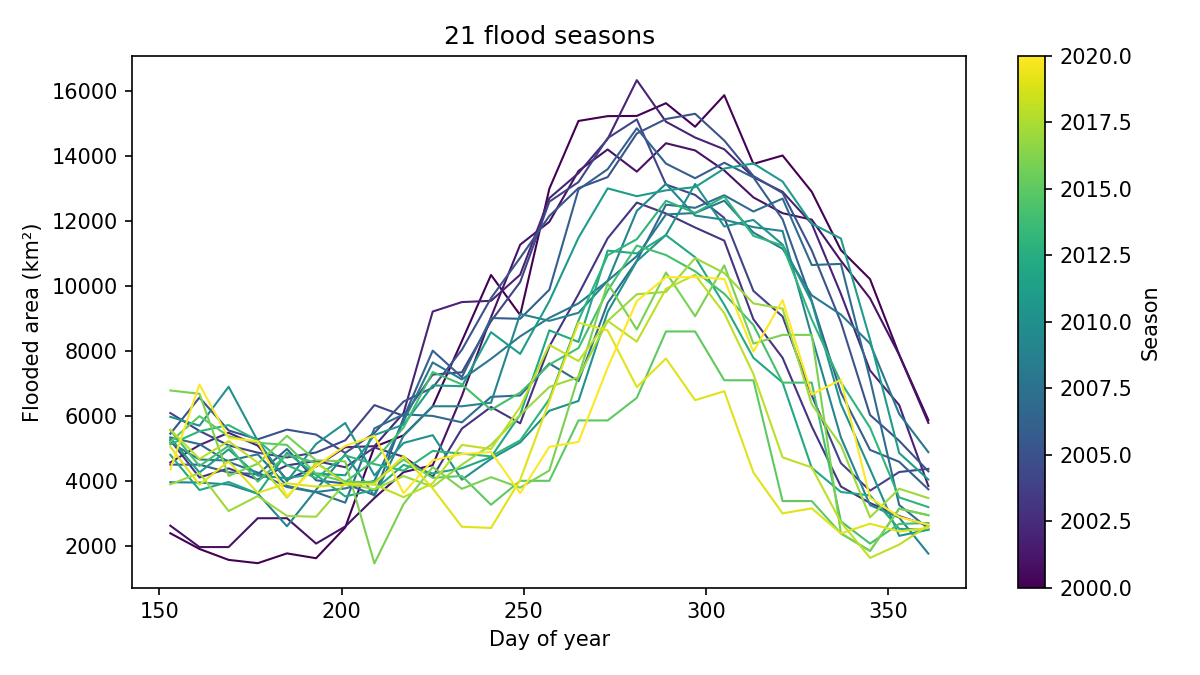

,test,statistic,p,note
0,Mann-Kendall (peak ~ year),-0.695238,1.585326e-06,tau
1,OLS HC3 (peak ~ year),-313.924403,6.573890e-14,"km2/year, CI95 [-396; -232], R2=0.770"
2,Mann-Whitney (peak before vs from 2010),101.000000,1.355261e-03,"median 14619 vs 10860, n=10/11"
3,Levene (peak before vs from 2010),0.018758,8.925033e-01,std 1413 vs 1641
4,Kruskal-Wallis (peak_doy by flood size),0.533881,7.657187e-01,3 groups by peak tercile


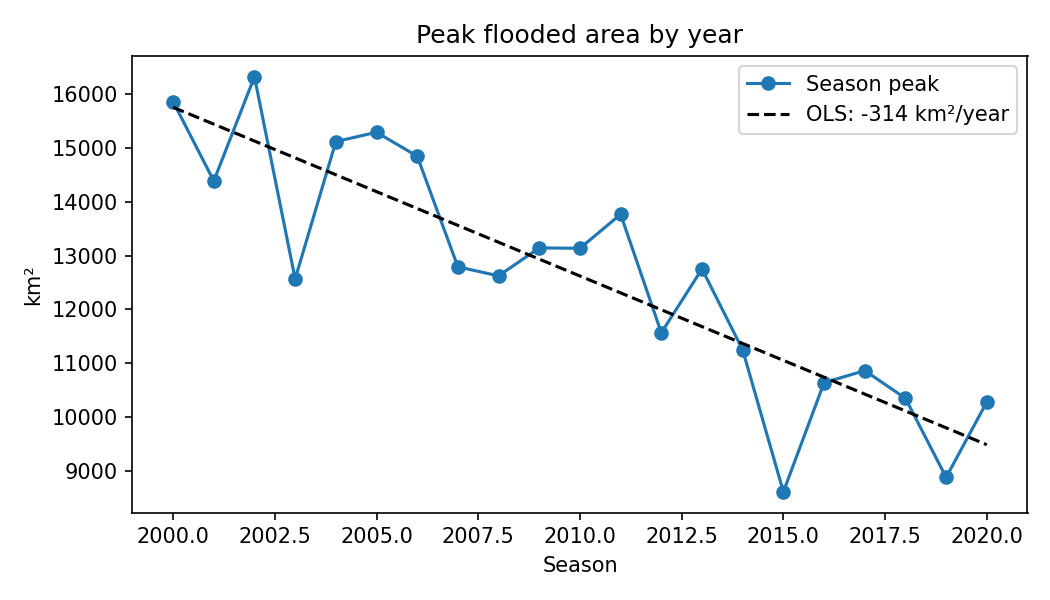

In [3]:
config = load_config("mekong")
Y = load_flood_matrix(config)
print("Shape:", Y.shape, "(seasons × steps)")
doys = [step_to_doy(config, s) for s in range(1, config["n_steps"] + 1)]
display(Image(FIGURES / "seasons_overlay.png", width=560))
display(pd.read_csv(TABLES / "eda_inference.csv"))
display(Image(FIGURES / "peak_trend.png", width=480))

## 4. Leakage-free rules

- **Climatology** (normal level) of a season = mean of the 5 **preceding** seasons, excluding itself.
- **Anomaly** a = observed value − climatology.
- **Forecast origin** t: only steps 1..t of the test season are known; the target is step t + h (h = 1, 2, 4 steps = 8, 16, 32 days).
- **φ** is estimated only from training seasons 2003..Y−1 when forecasting test season Y (yearly rolling origin).

Details: `anomar1_protocol.py::climatology`, `anomar1_protocol.py::training_seasons`, `anomar1_protocol.py::build_rows`

In [4]:
season = 2015
i = season - config["first_year"]
print("Climatology of 2015 uses seasons:", list(range(season - 5, season)))
print("Training seasons for test season 2015:", training_seasons(season, config["first_year"]))
c = climatology(Y, i)
pd.DataFrame({"y": Y[i], "climatology": c, "anomaly": Y[i] - c}, index=doys).round(0).iloc[::4]

Climatology of 2015 uses seasons: [2010, 2011, 2012, 2013, 2014]
Training seasons for test season 2015: [2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014]


,y,climatology,anomaly
153,5213.0,5368.0,-155.0
185,5119.0,4461.0,658.0
217,4667.0,5080.0,-413.0
249,4016.0,6228.0,-2213.0
281,6565.0,11443.0,-4877.0
313,7105.0,10788.0,-3683.0
345,1861.0,4807.0,-2946.0


In [5]:
for h in HORIZONS:
    origins = forecast_origins(config["n_steps"], h)
    print(f"h = {h} ({HORIZON_DAYS[h]} days): origins t = {origins.start}..{origins.stop - 1}, {len(origins)} forecasts per season")

h = 1 (8 days): origins t = 3..26, 24 forecasts per season
h = 2 (16 days): origins t = 3..25, 23 forecasts per season
h = 4 (32 days): origins t = 3..23, 21 forecasts per season


## 5. One forecast by hand: season 2015, origin t = 10

1. Build the forecast rows of training seasons 2003–2014 at horizon h.
2. φ = regression through the origin of the step-t anomaly on the step-(t − 1) anomaly: φ = Σ x·y / Σ x².
3. Forecast = climatology at the target + φ^h × today's anomaly.
4. Compare with the matching row of `predictions.csv`: they must agree.

Details: `anomar1_protocol.py::estimate_phi`, `anomar1_protocol.py::anom_ar1`, `anomar1_forecast.py::run`

In [6]:
origin = 10
saved = pd.read_csv(TABLES / "predictions.csv")
for h in HORIZONS:
    train = build_rows(Y, config, training_seasons(season, config["first_year"]), h)
    phi = estimate_phi(train)
    by_hand = c[origin + h - 1] + phi**h * (Y[i, origin - 1] - c[origin - 1])
    in_table = saved.query("model == 'anom_ar1' and season == @season and t == @origin and h == @h")["pred"].item()
    print(f"h = {h}: φ = {phi:.3f}, {len(train)} training rows | by hand {by_hand:8.1f} | in table {in_table:8.1f} | "
          f"match: {abs(by_hand - in_table) < 1e-6}")

h = 1: φ = 0.883, 288 training rows | by hand   3961.3 | in table   3961.3 | match: True
h = 2: φ = 0.918, 276 training rows | by hand   4385.3 | in table   4385.3 | match: True
h = 4: φ = 0.919, 252 training rows | by hand   6495.2 | in table   6495.2 | match: True


φ is re-estimated for every test season and every horizon (each horizon has a slightly different set of rows).
φ sits around 0.85–0.94 and drifts down across folds: deviations from normal fade faster in recent seasons.

Details: `anomar1_forecast.py::phi_record`

h,1,2,4
test_season,,,
2010,0.8985,0.9355,0.9262
2011,0.8960,0.9264,0.9151
2012,0.8906,0.9239,0.9106
2013,0.8930,0.9246,0.9304
2014,0.8896,0.9202,0.9244
2015,0.8833,0.9179,0.9193
2016,0.8888,0.9237,0.9335
2017,0.8664,0.9014,0.9109
2018,0.8601,0.8940,0.9032


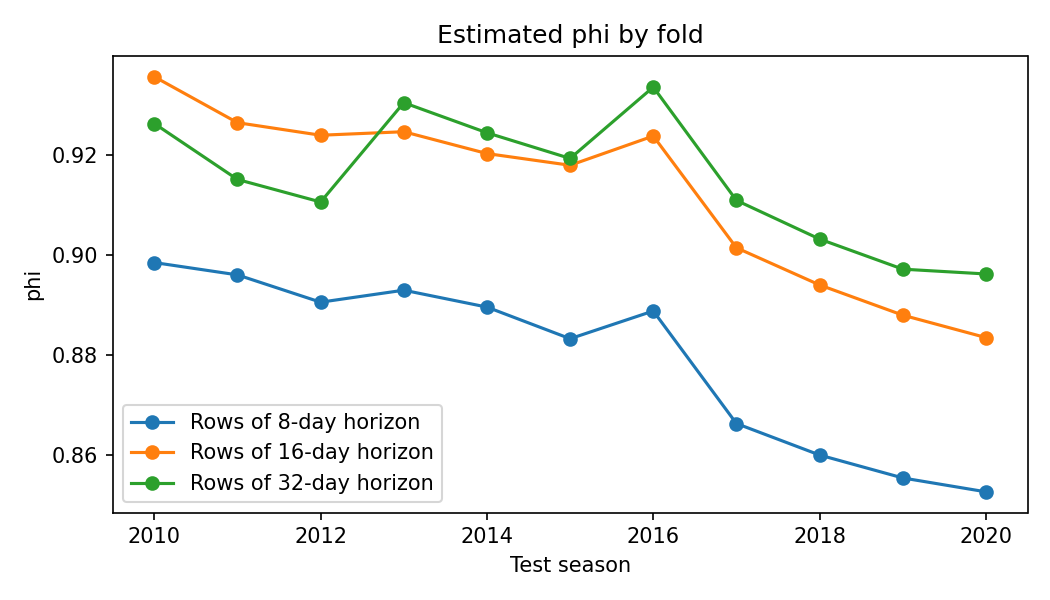

In [7]:
phi = pd.read_csv(TABLES / "phi_by_fold.csv")
display(phi.query("model == 'anom_ar1'").pivot(index="test_season", columns="h", values="phi").round(4))
display(Image(FIGURES / "phi_by_fold.png", width=480))

## 6. Overall results

Pooled RMSE over all forecasts of the 11 test seasons (2010–2020). Comparisons are tested at the **season level**
(n = 11), because errors of steps within one season are strongly correlated.

Details: `anomar1_evaluate.py::rmse_table`, `anomar1_evaluate.py::compare_with_anom_ar1`

In [8]:
display(pd.read_csv(TABLES / "rmse.csv").set_index("model"))
display(tests)

,1,2,4
model,,,
anom_ar1,1090.0,1375.0,1687.0
anom_ar1_w7,1084.0,1355.0,1682.0
clim5,1812.0,1845.0,1916.0
persistence,1312.0,2068.0,3456.0


,model,h,n_seasons,rmse_ratio,wins,mse_diff_pct,mse_diff_pct_ci_low,mse_diff_pct_ci_high,p_t,p_wilcoxon,p_tost,p_t_holm
0,anom_ar1_w7,1,11,0.9944,8,-1.0719,-3.0141,0.8702,0.3325,0.3223,0.0000,0.6650
1,anom_ar1_w7,2,11,0.9851,9,-3.5064,-5.7821,-1.2308,0.0208,0.0371,0.0001,0.1151
2,anom_ar1_w7,4,11,0.9972,7,-1.5561,-6.3951,3.2829,0.7663,0.4922,0.0025,0.7663
3,clim5,1,11,1.6630,0,185.3653,66.1157,304.6149,0.0192,0.0010,0.9989,0.1151
4,clim5,2,11,1.3417,1,71.0013,6.9059,135.0968,0.0581,0.0098,0.9767,0.2326
5,clim5,4,11,1.1359,5,18.2491,-12.9342,49.4323,0.1683,0.1748,0.5105,0.5049
6,persistence,1,11,1.2045,1,67.1704,11.9044,122.4363,0.0042,0.0049,0.9876,0.0296
7,persistence,2,11,1.5033,0,180.3060,61.8986,298.7134,0.0003,0.0010,0.9995,0.0021
8,persistence,4,11,2.0484,0,486.9323,210.5814,763.2831,0.0000,0.0010,1.0000,0.0002


## 7. By condition

AnomAR1 RMSE by flood phase (from the target day) and by flood size of the test season (the 11 seasons split into
3 groups by peak). Errors are largest during the **falling** phase; at 32 days the **small-flood** seasons are hardest.

Details: `anomar1_evaluate.py::condition_tables`, `anomar1_diagnostics.py::plot_seasons`

,rising,peak,falling
h,,,
1,897.0,1068.0,1304.0
2,1154.0,1391.0,1578.0
4,1357.0,1692.0,1927.0


,small,medium,large
h,,,
1,1179.0,1196.0,896.0
2,1488.0,1367.0,1260.0
4,1885.0,1400.0,1675.0


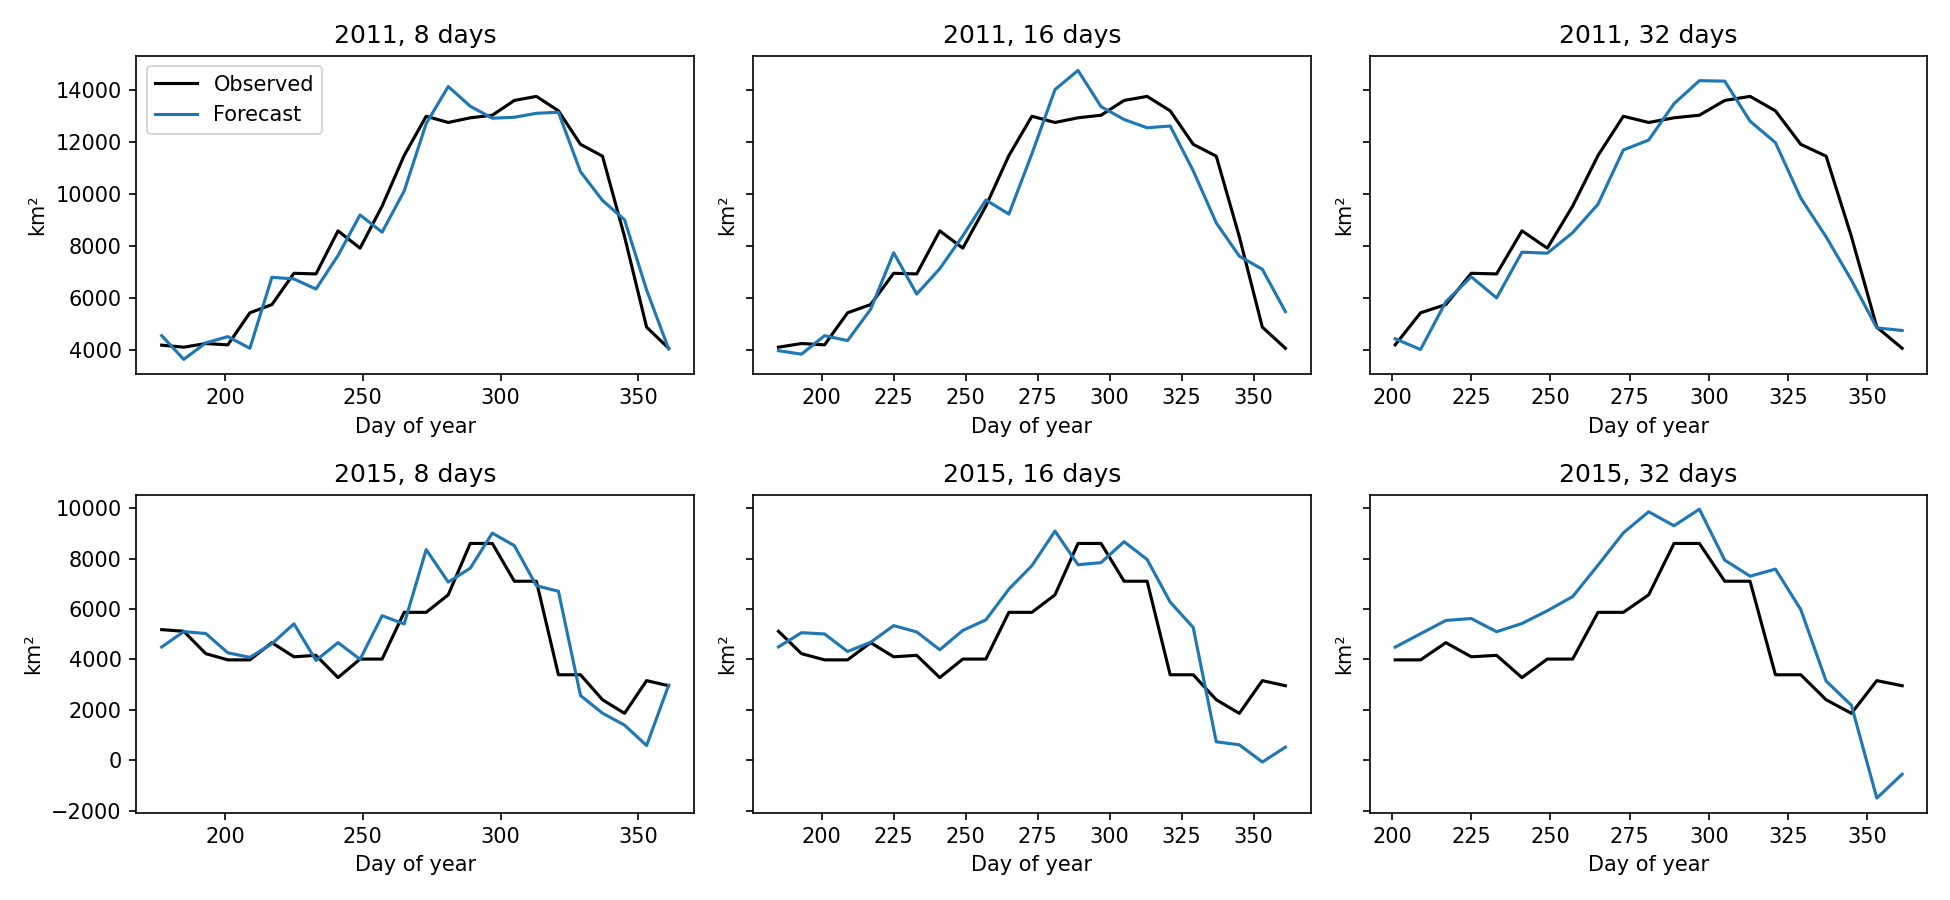

In [9]:
display(pd.read_csv(TABLES / "rmse_by_phase.csv").set_index("h").round(0))
display(pd.read_csv(TABLES / "rmse_by_magnitude.csv").set_index("h").round(0))
display(Image(FIGURES / "typical_seasons.png", width=900))

## 8. Side checks: is φ^h reasonable, what do the residuals look like

- **Direct φ:** instead of φ^h, estimate one coefficient per horizon (target anomaly on today's anomaly).
  RMSE drops slightly (about 1% at 16 and 32 days). This is a sensitivity check; it does not change the main baseline.
- **Residuals:** the mean of (observed − forecast) is negative, so AnomAR1 forecasts slightly **too high**,
  especially at 32 days. A likely reason: peaks fall over the years, so the normal level taken from the 5 previous
  seasons is too high.
- Residual autocorrelation at 16 and 32 days is **expected** for multi-step forecasts (neighbouring errors share
  part of the same shocks); it is not a sign that the model is wrong.

Details: `anomar1_diagnostics.py::compare_direct_phi`, `anomar1_diagnostics.py::residual_tests`

,h,days,rmse_phi_pow_h,rmse_direct_phi
0,1,8,1089.6,1088.4
1,2,16,1375.4,1355.9
2,4,32,1687.1,1675.3


,h,mean_bias_km2,mean_acf_1,seasons_lb_p_below_05,n_seasons
0,1,-83.791,-0.139,0,11
1,2,-130.195,0.357,4,11
2,4,-301.777,0.485,7,11


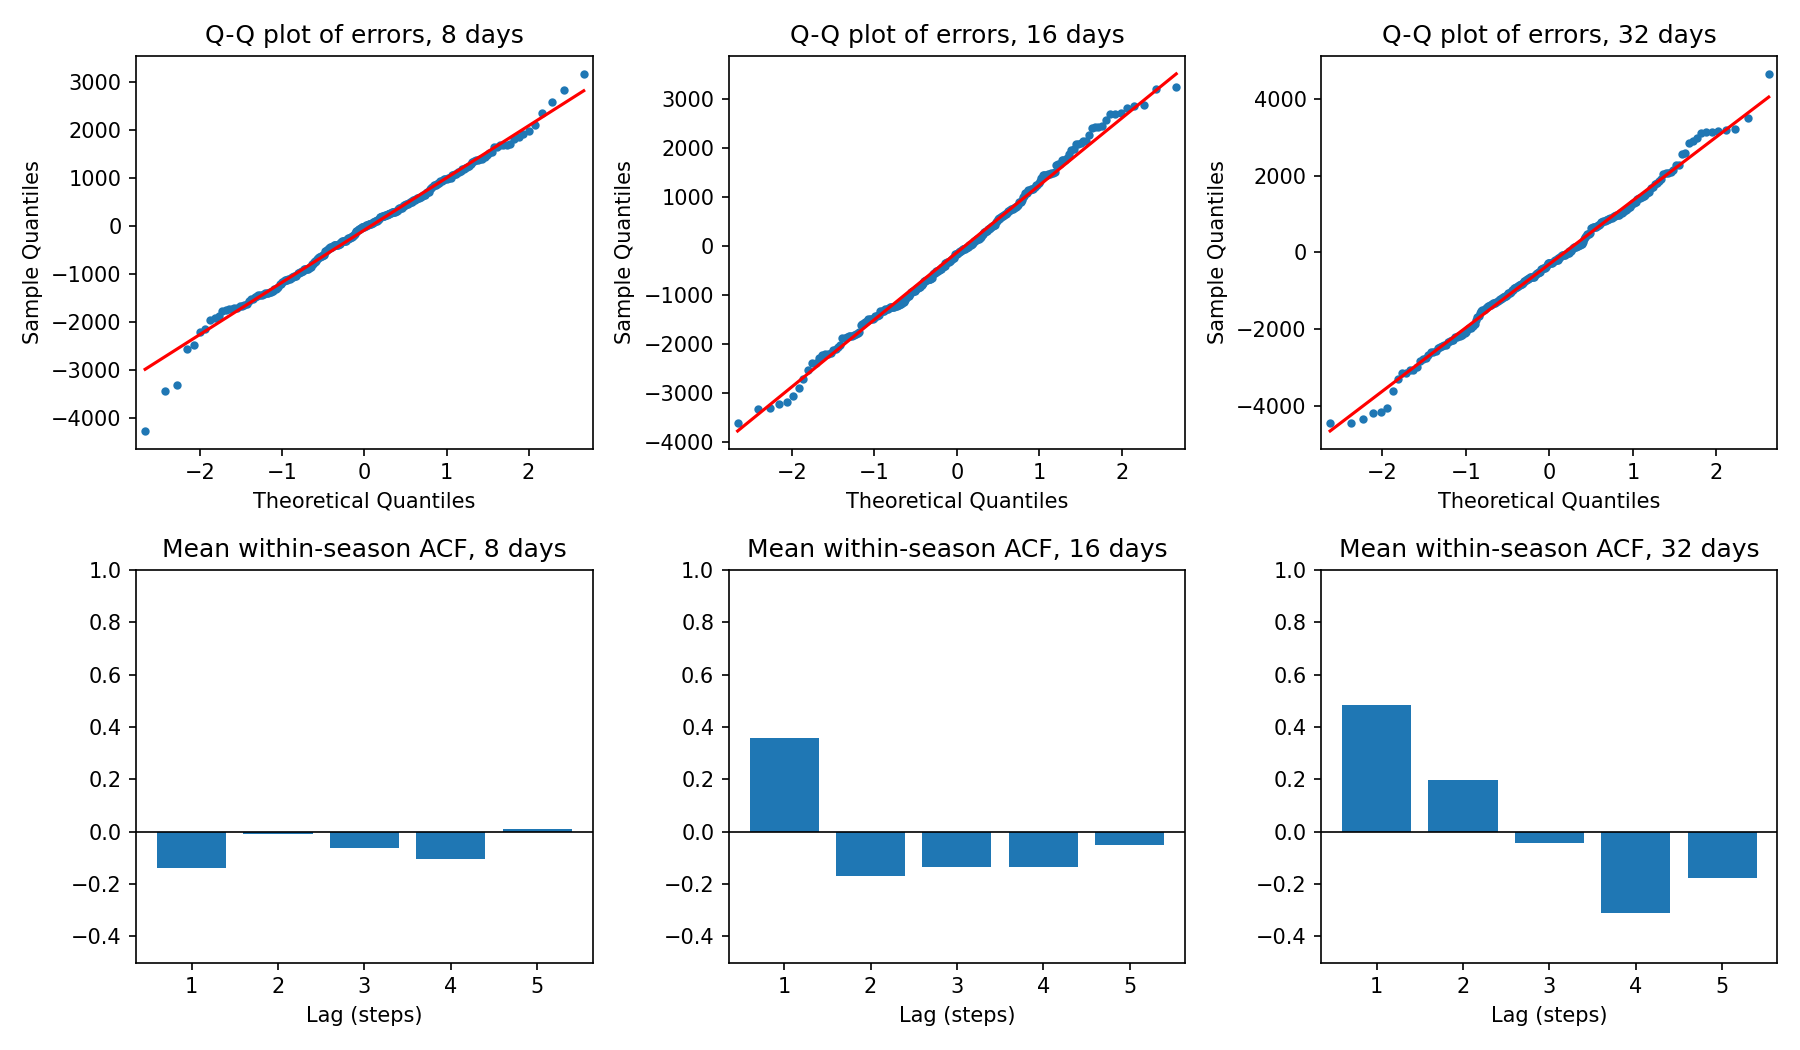

In [10]:
display(pd.read_csv(TABLES / "phi_direct_sensitivity.csv").round(1))
display(pd.read_csv(TABLES / "residual_summary.csv").round(3))
display(Image(FIGURES / "residual_diagnostics.png", width=900))

## 9. Safe wording and limitations

- Say: "AnomAR1 clearly beats persistence at every horizon and beats clim5 in raw numbers; training on 7 or all
  seasons gives equivalent results." Do not call AnomAR1 "the best model": it is the **baseline** others must beat.
- AnomAR1 here equals the `anom_ar1` rows in the GAM, LightGBM and Chronos-2 tables exactly: every comparison in the
  team uses the same baseline.
- Holm p corrects within the 9 comparisons of this table; "not significantly different" does not mean "equivalent".
- Only 11 test seasons and one region-wide series: confidence intervals are wide.
- The model can forecast negative areas late in the season (not clipped at 0, following the shared protocol).
- The target is a product derived from MODIS images (Vu et al. 2022), not a direct measurement.

See also: `src/AnomAR1/README.md`.